In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ১. ডেটা ডাউনলোড করা (শুধু সেরা ১০,০০০ শব্দ রাখব)
vocab_size = 10000
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)

print("Data Loaded Successfully! ✅")
print(f"Total Reviews for training: {len(X_train)}")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Data Loaded Successfully! ✅
Total Reviews for training: 25000


In [3]:
# আমরা সব রিভিউ ২৫০ শব্দের বানাব
max_length = 250

# যাদের রিভিউ ছোট, তাদের সাথে '0' যোগ হবে। বড় হলে কেটে ফেলা হবে।
X_train = pad_sequences(X_train, maxlen=max_length, padding='post', truncating='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post', truncating='post')

print(f"New Shape of Data: {X_train.shape}")
print("All reviews are now equal size! 📏")

New Shape of Data: (25000, 250)
All reviews are now equal size! 📏


In [15]:
# আপগ্রেডেড আর্কিটেকচার (Bidirectional LSTM)
model = tf.keras.models.Sequential([
    # ১. Embedding
    tf.keras.layers.Embedding(input_dim=10000, output_dim=32, input_length=250),

    # ২. Bidirectional LSTM (The Upgrade)
    # এটা পড়ার সময় দুই দিক থেকেই কনটেক্সট নেবে (বাম-ডান এবং ডান-বাম)
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),

    # ৩. একটু এক্সট্রা ব্রেইন পাওয়ার (Dense Layer)
    tf.keras.layers.Dense(64, activation='relu'),

    # ৪. ড্রপআউট (যাতে মুখস্থ না করে - রিসার্চারদের ট্রিক)
    tf.keras.layers.Dropout(0.5),

    # ৫. আউটপুট
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# কম্পাইল করা
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Upgraded Bidirectional Model Built! 🚀")
model.summary()

Upgraded Bidirectional Model Built! 🚀


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
print("Training Started... Please wait ⏳")

# আমরা ৫ বার (Epochs=5) পুরো বইটা রিভিশন দেব
history = model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))

print("Training Finished! 🎉")

Training Started... Please wait ⏳
Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 218s 273ms/step - accuracy: 0.6713 - loss: 0.5736 - val_accuracy: 0.8378 - val_loss: 0.3747
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 260s 271ms/step - accuracy: 0.8817 - loss: 0.3078 - val_accuracy: 0.8431 - val_loss: 0.3727
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 264s 273ms/step - accuracy: 0.9147 - loss: 0.2348 - val_accuracy: 0.8516 - val_loss: 0.3760
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 209s 268ms/step - accuracy: 0.9339 - loss: 0.1882 - val_accuracy: 0.8343 - val_loss: 0.4797
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 261s 266ms/step - accuracy: 0.9422 - loss: 0.1645 - val_accuracy: 0.8476 - val_loss: 0.4387
Training Finished! 🎉


In [17]:
# ১. ডিকশনারি নামানো (ইংরেজি শব্দ -> সংখ্যা)
word_index = imdb.get_word_index()

def predict_sentiment(text):
    # টেক্সটকে ছোট হাতের করা এবং শব্দগুলো আলাদা করা
    words = text.lower().split()

    # শব্দগুলোকে নাম্বারে কনভার্ট করা (যেগুলো ডিকশনারিতে নেই সেগুলোকে 2 দেব)
    encoded = [word_index.get(word, 2) + 3 for word in words]

    # সাইজ ২৫০ করা (Padding)
    padded = pad_sequences([encoded], maxlen=250, padding='post', truncating='post')

    # প্রেডিকশন
    prediction = model.predict(padded)[0][0]

    # রেজাল্ট দেখানো
    print(f"\nReview: '{text}'")
    print(f"Confidence Score: {prediction:.4f}") # (০ থেকে ১ এর মধ্যে)

    if prediction > 0.5:
        print("Result: POSITIVE Review! (ভালো) 😊")
    else:
        print("Result: NEGATIVE Review! (বাজে) 😡")

# ২. চলো টেস্ট করি!
predict_sentiment("This movie is amazing and I loved it")
predict_sentiment("Worst movie ever, total waste of time")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step

Review: 'This movie is amazing and I loved it'
Confidence Score: 0.9881
Result: POSITIVE Review! (ভালো) 😊
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step

Review: 'Worst movie ever, total waste of time'
Confidence Score: 0.0030
Result: NEGATIVE Review! (বাজে) 😡


In [18]:
def predict_sentiment(text):
    words = text.lower().split()
    encoded = []

    for word in words:
        # ১. শব্দটা কি ডিকশনারিতে আছে?
        if word in word_index:
            idx = word_index[word] + 3 # ৩ ঘর পিছিয়ে সেট করা

            # ২. শব্দটা কি আমাদের ১০,০০০ লিমিটের মধ্যে?
            if idx >= 10000:
                idx = 2 # লিমিটের বাইরে হলে 'Unknown' (2) ধরে নাও
        else:
            idx = 2 # ডিকশনারিতে না থাকলেও 'Unknown' (2)

        encoded.append(idx)

    # প্যাডিং করা
    padded = pad_sequences([encoded], maxlen=250, padding='post', truncating='post')

    # প্রেডিকশন
    prediction = model.predict(padded)[0][0]

    # রেজাল্ট দেখানো
    print(f"\nReview: '{text}'")
    print(f"Confidence Score: {prediction:.4f}")

    if prediction > 0.5:
        print("Result: POSITIVE Review! (ভালো) 😊")
    else:
        print("Result: NEGATIVE Review! (বাজে) 😡")

# এবার টেস্ট করো (আর এরর দেবে না)
predict_sentiment("The movie was so long that I finished my graduation while watching it")
predict_sentiment("The acting was good but the story was total garbage")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step

Review: 'The movie was so long that I finished my graduation while watching it'
Confidence Score: 0.4285
Result: NEGATIVE Review! (বাজে) 😡
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step

Review: 'The acting was good but the story was total garbage'
Confidence Score: 0.1078
Result: NEGATIVE Review! (বাজে) 😡


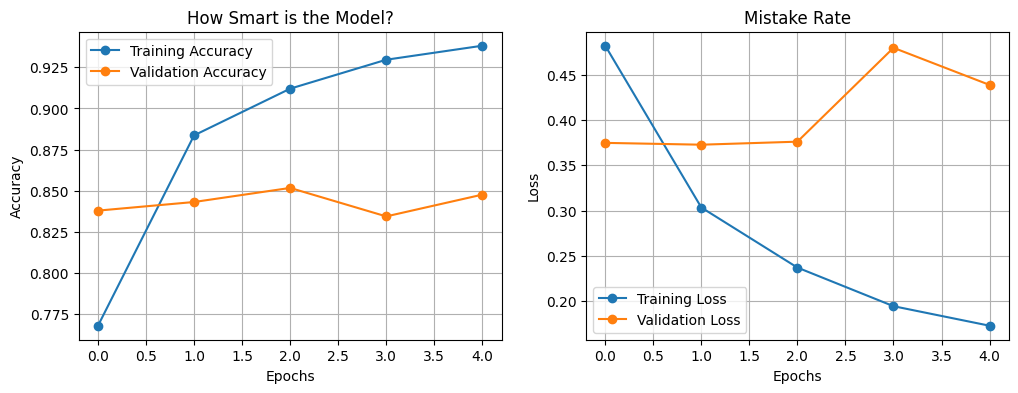

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# ১. একুরেন্সি গ্রাফ (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('How Smart is the Model?')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# ২. লস গ্রাফ (Loss/Mistakes)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Mistake Rate')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step


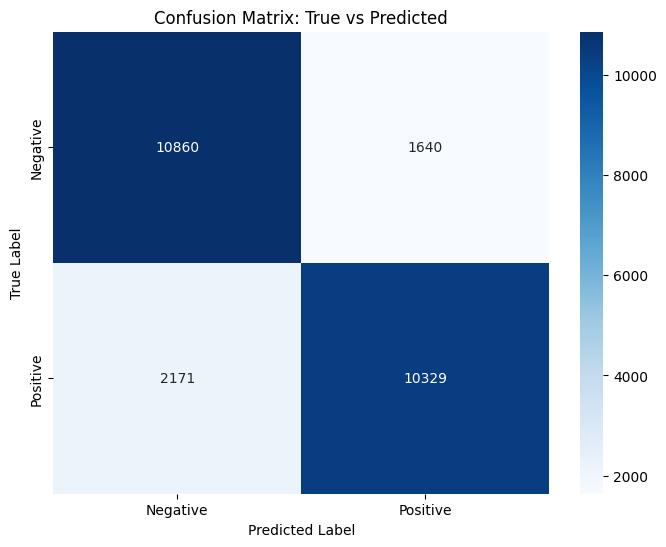

In [20]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# ১. টেস্ট ডেটার ওপর প্রেডিকশন নেওয়া
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype("int32") # ০.৫ এর বেশি হলে ১, কম হলে ০

# ২. কনফিউশন ম্যাট্রিক্স তৈরি
cm = confusion_matrix(y_test, y_pred_classes)

# ৩. সুন্দর করে প্লট করা
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix: True vs Predicted')
plt.show()

In [22]:
# মডেল সেভ করা (.h5 ফরম্যাটে)
model.save('sentiment_model_lstm.h5')
print("Model Saved Successfully! ✅")

Model Saved Successfully! ✅
